# Can ENSO indicators improve agricultural commodity price forecasting?

Introduction · 1. Data · 2. Descriptive analysis · 3. Base model · 4. Ridge with and without climate · 5. One commodity at a time · 6. Boosted trees · 7. Statistical test · Conclusion

## Introduction

What is ENSO? The El Niño–Southern Oscillation (ENSO) is a natural climate cycle of the tropical Pacific Ocean.
Every few years the surface of the ocean becomes warmer than usual (El Niño) or colder than usual (La Niña).
An event lasts from several months to more than a year, and it changes rain and temperature in many farming regions of the world.
For example, El Niño often brings drought to South-East Asia and Australia, while La Niña often brings dry weather to Argentina and the south of the United States.

Weather changes harvests, harvests change supply, and supply changes prices.
ENSO moves slowly and is measured every month, so it is known before the crops are harvested.
It could therefore tell us something about future prices that past prices do not.

Does ENSO help to predict next month's return of agricultural commodities, beyond what past prices already say?


1. We build a monthly table of commodity returns and of the ENSO index (ONI).
2. We look at the average return of each commodity in El Niño, La Niña and neutral months.
3. We build a base model that uses prices only.
4. We add ONI to a Ridge regression and compare the result with and without it.
5. We repeat the comparison for each commodity on its own.
6. We check whether a more flexible model (boosted trees) changes the answer.


## 1 — Data

- **Prices**: World Bank Pink Sheet, monthly averages, from 1960, downloaded automatically below.
  Main study: wheat, maize, soybeans. Extra commodities found in the literature to be ENSO-sensitive:
  vegetable oils, cocoa, coffee, sugar, rice, cotton.
  https://www.worldbank.org/en/research/commodity-markets

- **Climate**: NOAA ONI (3-month average of the Niño 3.4 sea temperature anomaly)
  https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skfin.plot import line, heatmap

In [3]:
GITHUB = "https://raw.githubusercontent.com/jassr7/ENSO_project/main/"

In [4]:
prices = pd.read_excel(GITHUB + "CMO-Historical-Data-Monthly.xlsx", sheet_name="Monthly Prices",
                       header=4, skiprows=[5], index_col=0)

commodities = ["Wheat, US HRW", "Maize", "Soybeans",
               "Palm oil", "Soybean oil", "Coconut oil",
               "Cocoa", "Coffee, Arabica", "Coffee, Robusta",
               "Sugar, world", "Rice, Thai 5% ", "Cotton, A Index"]
prices = prices[commodities]
prices.index = pd.to_datetime(prices.index, format="%YM%m") + pd.offsets.MonthEnd(0)

returns = np.log(prices.astype(float)).diff()

We read the ONI file. It has one value per month, starting in January 1950.

In [5]:
oni = pd.read_csv(GITHUB + "oni.ascii.txt", sep=r"\s+")
oni.index = pd.date_range("1950-01-31", periods=len(oni), freq="ME")
oni = oni["ANOM"]

**No look-ahead.** A row dated *t* only contains what is known at the end of month *t*;
it will be used to predict the return of month *t+1*.
The ONI centred on month *m* uses month *m+1* which is published at the start of *m+2* .So we shift ONI by 2 months.

**ENSO phase** NOAA rule: El Niño if ONI ≥ 0.5, La Niña if ONI ≤ −0.5 and otherwise Neutral.

We put returns, ONI and the ENSO phase in one table and save it.

In [6]:
data = returns.copy()
data["oni"] = oni
data["oni"] = data["oni"].shift(2)

data["phase"] = "Neutral"
data.loc[data["oni"] >= 0.5, "phase"] = "El Nino"
data.loc[data["oni"] <= -0.5, "phase"] = "La Nina"

data = data.dropna()
data.to_csv("data/enso_commodities.csv")

print(data.index[0].date(), "to", data.index[-1].date(), "-", len(data), "months")
data.tail()

1960-03-31 to 2024-12-31 - 778 months


,"Wheat, US HRW",Maize,Soybeans,Palm oil,Soybean oil,Coconut oil,Cocoa,"Coffee, Arabica","Coffee, Robusta","Sugar, world","Rice, Thai 5%","Cotton, A Index",oni,phase
2024-08-31,-0.036826,-0.040865,-0.160156,0.039968,-0.045156,0.093369,-0.030226,0.016740,-0.000186,-0.048790,-0.001696,-0.017741,0.18,Neutral
2024-09-30,0.072418,0.082471,-0.022289,0.052428,0.011980,0.069853,-0.052892,0.060733,0.118880,0.099255,-0.015398,0.031905,0.06,Neutral
2024-10-31,0.011649,0.028611,0.122036,0.091731,0.047776,-0.004255,0.020284,-0.003751,-0.085756,0.030056,-0.118861,0.013846,-0.04,Neutral
2024-11-30,-0.072573,0.056161,-0.014718,0.081385,0.044900,0.083382,0.170471,0.097059,0.018750,-0.024657,-0.007797,-0.025554,-0.12,Neutral
2024-12-31,-0.006246,0.006271,-0.062450,0.017932,-0.073865,0.049112,0.267928,0.118475,0.045899,-0.031828,0.030831,-0.019572,-0.19,Neutral


**Sample period.** Before 1973 grain prices were partly administered (US price supports, fixed exchange rates):
many months show no price change at all. So maybe it's a good idea to start from 1980 and avoid this effect.


In [7]:
START_EVAL = "1980-01-01"

A first look at the data: the cumulative returns of wheat and soybeans.

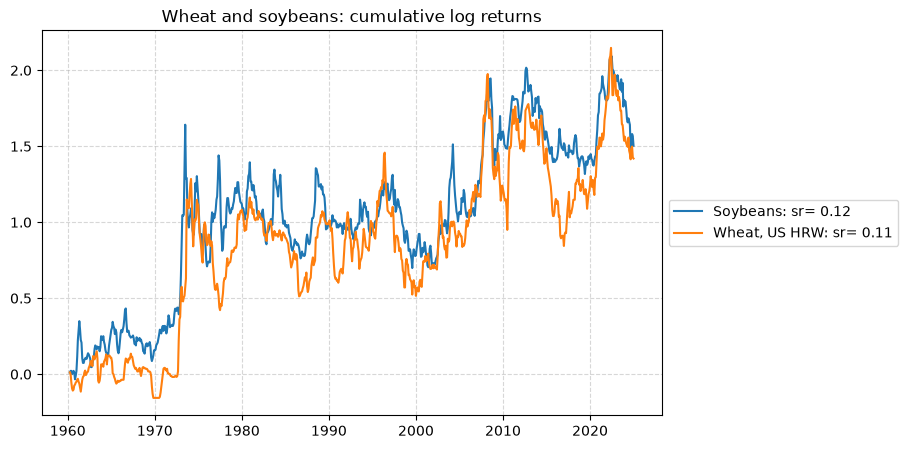

In [8]:
line(data[["Wheat, US HRW", "Soybeans"]], cumsum=True, title="Wheat and soybeans: cumulative log returns")

## 2 — Descriptive analysis

Before any model, we look at the raw link between ENSO and prices:
what is the average return of each commodity in each ENSO phase?

The table and the heatmap show the average return per year (blue = prices rise, red = prices fall).

phase,La Nina,Neutral,El Nino
"Wheat, US HRW",0.07,0.03,-0.06
Maize,0.12,-0.05,0.07
Soybeans,0.02,-0.02,0.11
Palm oil,-0.05,0.02,0.11
Soybean oil,0.00,0.00,0.10
Coconut oil,-0.08,0.00,0.18
Cocoa,0.01,0.00,0.17
"Coffee, Arabica",-0.00,0.05,0.03
"Coffee, Robusta",-0.03,0.04,0.08
"Sugar, world",0.06,-0.03,0.10


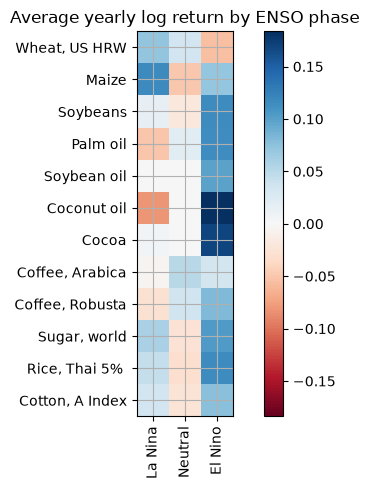

In [9]:
by_phase = data.groupby("phase")[commodities].mean() * 12
by_phase = by_phase.loc[["La Nina", "Neutral", "El Nino"]]

heatmap(by_phase, title="Average yearly log return by ENSO phase")
by_phase.T.round(2)

Most commodities rise during El Niño months, most strongly the tropical ones
(coconut oil, cocoa, palm oil, sugar). Wheat goes the other way: it falls in El Niño and rises in La Niña.
These are simple averages over the whole sample, not forecasts, and each phase contains only a few independent episodes.

The same table on the evaluation period only (from 1980), to leave out the commodity boom of the 1970s.

phase,La Nina,Neutral,El Nino
"Wheat, US HRW",0.09,0.04,-0.14
Maize,0.17,-0.08,0.02
Soybeans,0.07,-0.03,0.02
Palm oil,-0.07,0.04,0.05
Soybean oil,-0.00,0.01,0.02
Coconut oil,-0.09,0.00,0.15
Cocoa,0.00,-0.02,0.13
"Coffee, Arabica",-0.07,0.08,-0.02
"Coffee, Robusta",-0.09,0.04,0.03
"Sugar, world",0.09,-0.04,0.01


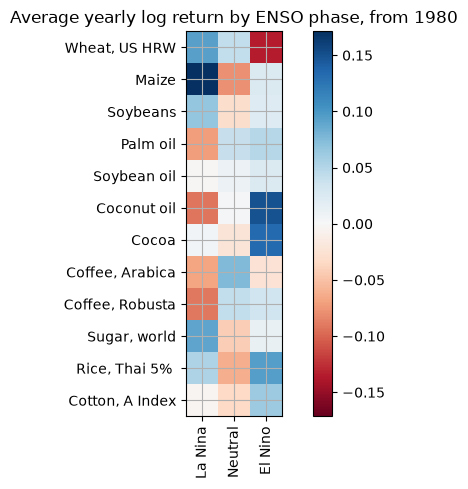

In [10]:
by_phase_1980 = data[START_EVAL:].groupby("phase")[commodities].mean() * 12
by_phase_1980 = by_phase_1980.loc[["La Nina", "Neutral", "El Nino"]]

heatmap(by_phase_1980, title="Average yearly log return by ENSO phase, from 1980")
by_phase_1980.T.round(2)

Without the 1970s, the El Niño effect stays for coconut oil, cocoa and rice, and wheat still falls in El Niño.
But it almost disappears for soybeans, palm oil and sugar: their full-sample result came mostly from the 1972–73 boom,
when all commodity prices rose together.

## 3 — Base model (no climate)

We follow the framework of the course. Instead of measuring the forecast error, we turn each forecast into positions and measure the Sharpe ratio of the resulting strategy.The Sharpe ratio is used here as a score for the forecasts, not as the profit of a real strategy, since World Bank prices are monthly averages that cannot be traded.

Our base model uses prices only. It is the momentum backtest applied to our 12 commodities.
The models with ENSO will have to beat this.
The model is trained on the past 36 months.

In [11]:
from skfin.backtesting import Backtester
from skfin.estimators.mean_variance import MeanVariance

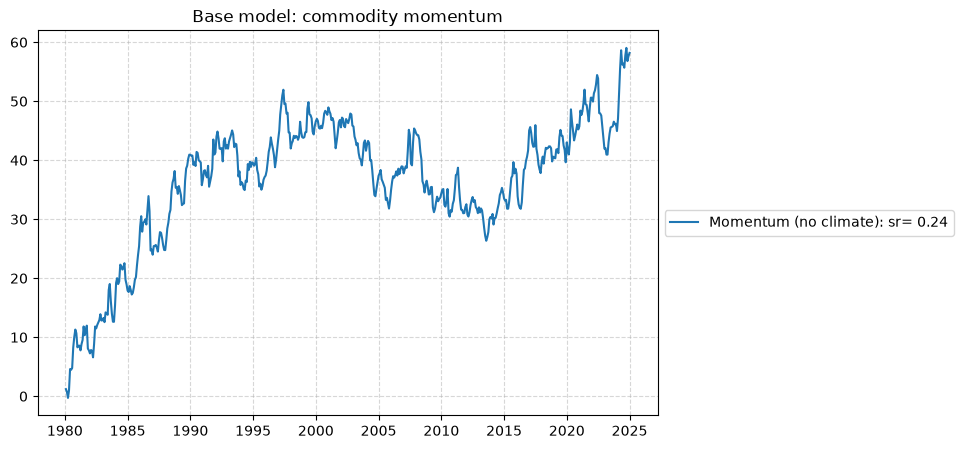

In [12]:
ret = data[commodities]
X = ret.rolling(12).mean()
y = ret.shift(-1)

m = Backtester(estimator=MeanVariance(), start_date=START_EVAL, name="Momentum (no climate)")
pnl_momentum = m.train(X, y, ret)

line(pnl_momentum, cumsum=True, title="Base model: commodity momentum")

## 4 — Ridge with and without climate

We now let a model learn the forecast. A `Ridge` regression predicts next month's returns,
then `MeanVariance` turns the forecast into positions.

We run it twice, with one difference only:

- prices only: the 12-month average returns of the 12 commodities;
- prices + ONI: the same table plus the ONI column.

If ENSO adds information, the second line should end above the first.
We train on the past 200 months instead of 36, because 36 months often contain no ENSO event at all.


In [13]:
from skfin.estimators.linear import Ridge
from skfin.plot import bar
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

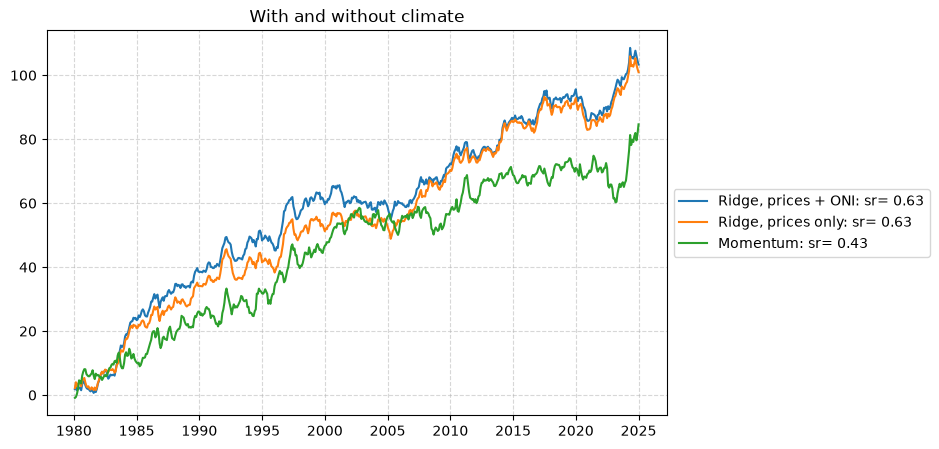

In [14]:
WINDOW = 200

X_price = ret.rolling(12).mean()
X_climate = X_price.copy()
X_climate["oni"] = data["oni"]

estimator = make_pipeline(StandardScaler(with_mean=False), Ridge(), MeanVariance())

m_momentum = Backtester(MeanVariance(), max_train_size=WINDOW, start_date=START_EVAL)
m_price = Backtester(estimator, max_train_size=WINDOW, start_date=START_EVAL)
m_climate = Backtester(estimator, max_train_size=WINDOW, start_date=START_EVAL)

pnls = {
    "Momentum": m_momentum.train(X_price, y, ret),
    "Ridge, prices only": m_price.train(X_price, y, ret),
    "Ridge, prices + ONI": m_climate.train(X_climate, y, ret),
}
line(pnls, cumsum=True, title="With and without climate")

-Ridge does better than momentum (Sharpe ratio 0.63 against 0.43), but adding ONI does not help (0.63 with ONI, 0.63 without).

-The two Ridge lines are almost the same strategy (correlation 0.95).

-One reason: positions sum to zero, so the strategy only bets on *differences* between commodities.
El Niño pushes most of them up together, and that common move is cancelled out.

What did the model learn? One Ridge model is fitted each month. We take its coefficient on ONI for each commodity and average it over all the months.

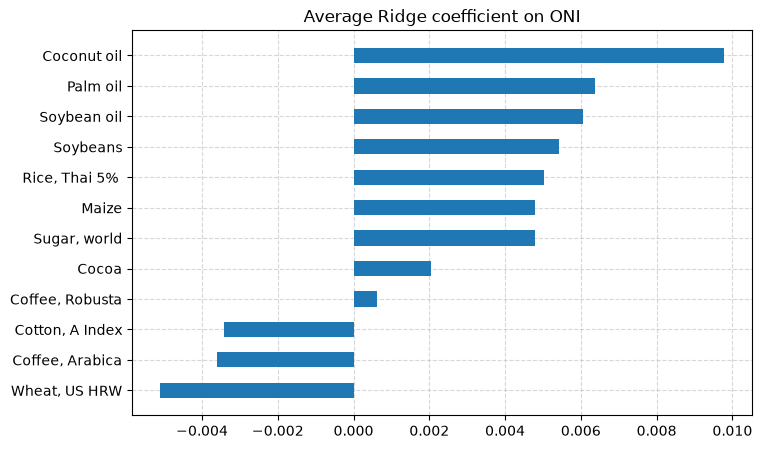

In [15]:
coef_oni = [m.named_steps["ridge"].coef_[:, -1] for m in m_climate.estimators_]
coef_oni = pd.DataFrame(coef_oni, columns=commodities, index=m_climate.h_.index)

bar(coef_oni.mean(), horizontal=True, title="Average Ridge coefficient on ONI")

The model did learn the pattern of Step 2. A positive coefficient for coconut oil, the other vegetable oils, soybeans and rice,
and a negative one for wheat. So ONI is not ignored. Its effect is real but too small to improve this strategy.

## 5 — One commodity at a time

In Step 4 positions summed to zero, so an El Niño that lifts most commodities together was cancelled out.
Here we test each commodity on its own as notebook 41 does for the stock market:
does ONI help predict whether a commodity will go up or down next month?

For each commodity we run two backtests: its own 12-month average return alone, then the same plus ONI.

In each backtest a `Ridge` regression predicts next month's return of one commodity,
and `TimingMeanVariance` turns the forecast into a position.

In [16]:
from skfin.estimators.mean_variance import TimingMeanVariance
from skfin.metrics import sharpe_ratio

In [17]:
timing = make_pipeline(StandardScaler(), Ridge(), TimingMeanVariance(a_min=-0.25, a_max=0.25))

pnl_price = {}
pnl_climate = {}
for c in commodities:
    r = ret[c]
    target = r.shift(-1)
    f_price = r.rolling(12).mean().to_frame()
    f_climate = f_price.copy()
    f_climate["oni"] = data["oni"]

    pnl_price[c] = Backtester(timing, max_train_size=WINDOW, start_date=START_EVAL).train(f_price, target, r)
    pnl_climate[c] = Backtester(timing, max_train_size=WINDOW, start_date=START_EVAL).train(f_climate, target, r)

pnl_price = pd.DataFrame(pnl_price)
pnl_climate = pd.DataFrame(pnl_climate)

The Sharpe ratio of each commodity, without and with ONI:

,Prices only,Prices + ONI
"Wheat, US HRW",0.01,0.28
Maize,-0.18,0.26
Soybeans,-0.11,0.22
Palm oil,0.09,0.30
Soybean oil,0.22,0.35
Coconut oil,0.50,0.69
Cocoa,0.02,-0.01
"Coffee, Arabica",0.04,0.06
"Coffee, Robusta",0.41,0.34
"Sugar, world",-0.04,0.11


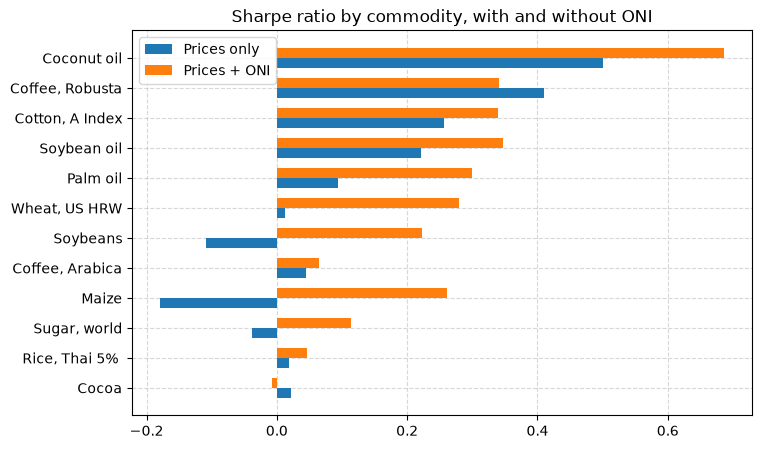

In [18]:
sr = pd.DataFrame({"Prices only": pnl_price.apply(sharpe_ratio),
                   "Prices + ONI": pnl_climate.apply(sharpe_ratio)})

bar(sr, horizontal=True, title="Sharpe ratio by commodity, with and without ONI")
sr.round(2)

Adding ONI raises the Sharpe ratio for 10 of the 12 commodities.
The largest gains are for maize,coconut oil, wheat, soybeans and palm oil.
Coffee and cocoa do not benefit.

All commodities together: the average of the 12 single-commodity strategies, without and with ONI.

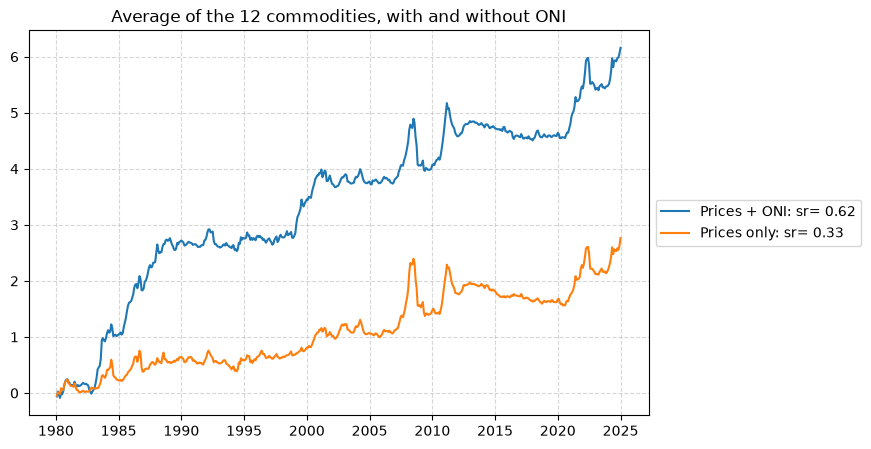

In [19]:
line({"Prices only": pnl_price.mean(axis=1), "Prices + ONI": pnl_climate.mean(axis=1)},
     cumsum=True, title="Average of the 12 commodities, with and without ONI")

Averaged over the 12 commodities, the Sharpe ratio goes from 0.33 without ONI to 0.62 with ONI.
But most of the gap opens between 1980 and 1995. After that the two lines move almost in parallel. Maybe the Enso effect disappears after 1995.

-We compute the gain from ONI (Sharpe ratio with ONI minus Sharpe ratio without) separately for 1980–1995 and 1996–2024.

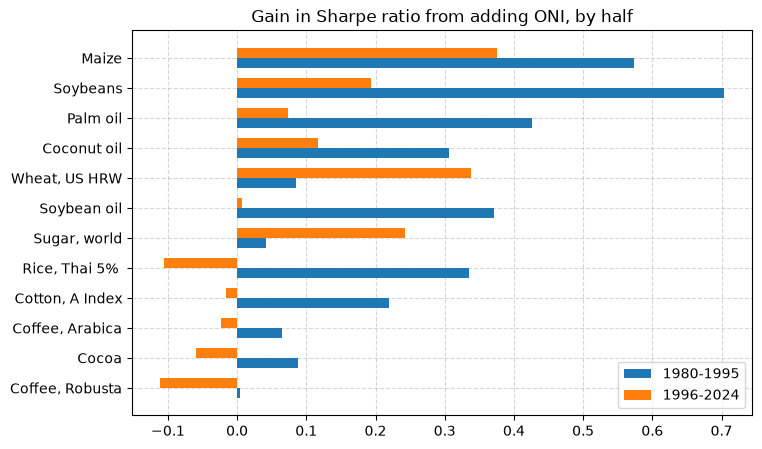

In [20]:
gain = pd.DataFrame({
    "1980-1995": pnl_climate[:"1995"].apply(sharpe_ratio) - pnl_price[:"1995"].apply(sharpe_ratio),
    "1996-2024": pnl_climate["1996":].apply(sharpe_ratio) - pnl_price["1996":].apply(sharpe_ratio),
})
bar(gain, horizontal=True, title="Gain in Sharpe ratio from adding ONI, by half")

The gain is not stable over time. It holds in both periods for maize, soybeans and coconut oil,
and wheat and sugar gain mostly in the second period. For palm oil, soybean oil, rice and cotton it is there in 1980–1995 and almost gone afterwards.

On average over the 12 commodities, ONI lifts the Sharpe ratio from 0.24 to 0.83 in 1980–1995, but only from 0.37 to 0.51 in 1996–2024.

So ENSO did add forecasting power for single commodities, mostly before the mid-1990s, and less since.
We are not sure about this finding but it's in line with Ubilava (2018), who finds that the ENSO effect on prices has weakened over time.

## 6 — Boosted trees

Ridge can only learn a linear effects.
Boosted trees (LightGBM) can learn other shapes for example an effect only when ONI is strongly positive.

We repeat the test of Step 5, one commodity at a time, with boosted trees.


In [21]:
from skfin.estimators import MultiLGBMRegressor

In [22]:
boosting = make_pipeline(MultiLGBMRegressor(min_child_samples=5, n_estimators=25),
                         TimingMeanVariance(a_min=-0.25, a_max=0.25))

pnl_price_gb = {}
pnl_climate_gb = {}
for c in commodities:
    r = ret[[c]]
    target = r.shift(-1)
    f_price = r.rolling(12).mean()
    f_climate = f_price.copy()
    f_climate["oni"] = data["oni"]

    pnl_price_gb[c] = Backtester(boosting, max_train_size=WINDOW, start_date=START_EVAL).train(f_price, target, r)
    pnl_climate_gb[c] = Backtester(boosting, max_train_size=WINDOW, start_date=START_EVAL).train(f_climate, target, r)

pnl_price_gb = pd.DataFrame(pnl_price_gb)
pnl_climate_gb = pd.DataFrame(pnl_climate_gb)

The average of the 12 single-commodity strategies, for Ridge and boosting, with and without ONI:

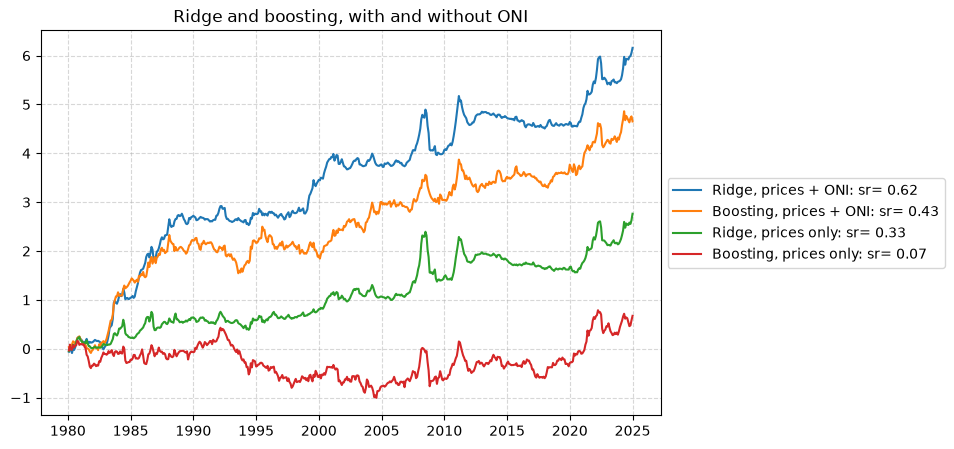

In [23]:
line({"Ridge, prices only": pnl_price.mean(axis=1),
      "Ridge, prices + ONI": pnl_climate.mean(axis=1),
      "Boosting, prices only": pnl_price_gb.mean(axis=1),
      "Boosting, prices + ONI": pnl_climate_gb.mean(axis=1)},
     cumsum=True, title="Ridge and boosting, with and without ONI")

Boosting points in the same direction as Ridge, but it does worse. Without ONI it is close to zero (Sharpe ratio 0.07);
with ONI it reaches 0.43, below Ridge with ONI (0.62).
The gain from ONI is again larger in the first period: from −0.13 to 0.60 in 1980–1995, and from 0.16 to 0.34 in 1996–2024.

So the more flexible model does not find more than the linear one. We see no sign of a strong non-linear effect of ONI.

## 7 — Statistical test

In Steps 5 and 6 the Sharpe ratio is higher with ONI than without. But a Sharpe ratio measured on 45 years of noisy returns is itself uncertain.
Could the gap between the two be only luck?

To answer, we use a bootstrap. We build 5,000 alternative histories by drawing blocks of 6 consecutive months at random from our results, and each time we recompute the gap:

- we take the same months for the two strategies, because they share the same market shocks and must be compared month by month;
- we draw blocks of consecutive months, not single months, so that the link between a month and the next ones is kept.

From the 5,000 gaps we read two numbers:

- the 95% interval: the range that contains 95% of the gaps;
- the p-value: the share of the gaps that are zero or negative. A small p-value (below 0.05) means that the gain is unlikely to be only luck.

In [24]:
def sharpe(x):
    return x.mean() / x.std() * np.sqrt(12)

def bootstrap_gap(with_oni, without, block=6, n_draws=5000):
    rng = np.random.default_rng(42)
    n = len(with_oni)
    gaps = []
    for i in range(n_draws):
        starts = rng.integers(0, n, size=n // block + 1)
        months = np.concatenate([np.arange(s, s + block) % n for s in starts])[:n]
        gaps.append(sharpe(with_oni[months]) - sharpe(without[months]))
    return np.array(gaps)

We test the average of the 12 single-commodity strategies, for Ridge and for boosting, on the full period and on the two sub-periods of Step 5.

In [25]:
models = {"Ridge": (pnl_climate, pnl_price), "Boosting": (pnl_climate_gb, pnl_price_gb)}
periods = [("1980", "2024"), ("1980", "1995"), ("1996", "2024")]

rows = {}
for name in models:
    with_oni = models[name][0].mean(axis=1)
    without = models[name][1].mean(axis=1)
    for start, end in periods:
        a = with_oni[start:end].values
        b = without[start:end].values
        gaps = bootstrap_gap(a, b)
        rows[name + ", " + start + "-" + end] = {"Sharpe gap": sharpe(a) - sharpe(b),
                                                 "95% low": np.percentile(gaps, 2.5),
                                                 "95% high": np.percentile(gaps, 97.5),
                                                 "p-value": (gaps <= 0).mean()}

test = pd.DataFrame(rows).T
test.round(3)

,Sharpe gap,95% low,95% high,p-value
"Ridge, 1980-2024",0.289,0.095,0.485,0.002
"Ridge, 1980-1995",0.588,0.158,0.987,0.003
"Ridge, 1996-2024",0.140,-0.040,0.330,0.062
"Boosting, 1980-2024",0.364,0.048,0.676,0.011
"Boosting, 1980-1995",0.728,0.116,1.314,0.008
"Boosting, 1996-2024",0.174,-0.191,0.534,0.174


- Full period (1980–2024): the gain from ONI is statistically significant for both models. For Ridge the gap is 0.29, with a 95% interval from 0.10 to 0.49 (p-value 0.002). For boosting it is 0.36, with an interval from 0.05 to 0.68 (p-value 0.011).
- 1980–1995: the gain is large and significant for both models (p-values 0.003 and 0.008).
- 1996–2024: the gain is small and not significant (p-values 0.06 for Ridge and 0.17 for boosting). Both intervals contain zero.

So the test confirms Step 5: ONI improved the strategies over the full period, but this comes from the first years. Since 1996 we cannot tell the gain from luck.




## Conclusion

Does ENSO help to predict the returns of agricultural commodities, beyond past prices?

What we found.

- Simple averages (Step 2): many commodities rise during El Niño months, most strongly the tropical ones (coconut oil, cocoa), while wheat falls. Part of the full-sample effect comes from the 1970s boom.
- All commodities together (Step 4): adding ONI does not help (Sharpe ratio 0.63 with ONI and 0.63 without). Positions sum to zero, so a common El Niño move is cancelled out.
- One commodity at a time (Step 5): adding ONI raises the Sharpe ratio for 10 of the 12 commodities, and the average goes from 0.33 to 0.62.
- Over time (Step 5): most of this gain comes from 1980–1995 (0.24 to 0.83). Since 1996 it is smaller (0.37 to 0.51).
- Boosted trees (Step 6): ONI helps boosting too (0.07 to 0.43), but boosting stays below Ridge (0.62). A more flexible model does not find more.
- Statistical test (Step 7): over 1980–2024 the gain from ONI is statistically significant for Ridge (p-value 0.002) and for boosting (p-value 0.011), but it is not significant after 1995.

Answer. ENSO added some forecasting power for single commodities, mostly before the mid-1990s and much less since.
The effect is small and it is not stable across periods, so it should be read with caution.

